# 04 · Árbol de decisión (M2)
## Predicción de casos mensuales y alertas de leishmaniosis cutánea en Cajamarca

**Objetivo:** entrenar el modelo M2 de `PIPELINE_PROPUESTO.md`, un árbol de decisión para las dos tareas, y compararlo con las líneas base de `03_baseline.ipynb`.

**Diseño (el mismo del baseline):**
- Unidad distrito × mes de Cajamarca, con los distritos que acumulan al menos 50 casos.
- Partición temporal: entrenamiento hasta 2018 y prueba 2019–2024. La prueba no se usa para elegir nada.
- Variables: las 7 de casos (`lag1`, `lag2`, `lag3`, `lag12`, `media3`, `mes_sin`, `mes_cos`). El clima no entra porque no cubre la prueba.
- Hiperparámetros elegidos con **validación temporal de ventana creciente**: se entrena con los años anteriores y se valida en 2014, 2015, 2016, 2017 y 2018 (paper 1).
- El árbol no necesita escalado ni SMOTE. El desbalance de la alerta se trata con `class_weight="balanced"`.

## 1. Inicializar e importar

In [1]:
import sys
import warnings
from itertools import product
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score, mean_absolute_error,
                             mean_squared_error, precision_recall_curve, precision_score, recall_score,
                             roc_auc_score)
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, export_text, plot_tree

sys.path.append("../src")
import preprocessing as pp

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12,
                     "figure.figsize": (12, 5)})
pd.options.display.float_format = "{:,.3f}".format

RAW = Path("../data/raw/datos_abiertos_vigilancia_leishmaniosis_2000_2024.csv")
PLOTS = Path("../results/plots")
RESULTS = Path("../results")
PLOTS.mkdir(parents=True, exist_ok=True)

REGION = "CAJAMARCA"
SEED = 42
AZUL, NARANJA, VERDE, GRIS = "#2a6f97", "#e07a1f", "#2d6a4f", "#8d99ae"

## 2. Datos

Se construyen exactamente igual que en el baseline, para que las métricas sean comparables.

In [2]:
casos = pp.clean_cases(pp.load_raw(RAW))
casos = casos[casos["departamento"] == REGION]
panel = pp.build_monthly_panel(casos)
train, test = pp.split_train_test(panel)
train = train.sort_values(["fecha_mes", "ubigeo"]).reset_index(drop=True)
test = test.sort_values(["fecha_mes", "ubigeo"]).reset_index(drop=True)

F = pp.FEATURES
print(f"Entrenamiento: {len(train):,} filas | Prueba: {len(test):,} filas | {panel['ubigeo'].nunique()} distritos")
print("Variables:", F)

Entrenamiento: 15,120 filas | Prueba: 5,040 filas | 70 distritos
Variables: ['lag1', 'lag2', 'lag3', 'lag12', 'media3', 'mes_sin', 'mes_cos']


### 2.1 Validación temporal

Cinco particiones de ventana creciente dentro del entrenamiento. Nunca se valida con meses anteriores a los de entrenamiento.

In [3]:
anio = train["fecha_mes"].dt.year
ANIOS_VAL = range(2014, 2019)
FOLDS = [(np.where(anio < a)[0], np.where(anio == a)[0]) for a in ANIOS_VAL]
for a, (tr, va) in zip(ANIOS_VAL, FOLDS):
    print(f"Valida {a}: entrena con {len(tr):,} filas (2001–{a - 1}), valida con {len(va):,}")

GRID = list(product([3, 4, 5, 6, 8, 10], [20, 50, 100, 200]))   # (max_depth, min_samples_leaf)

Valida 2014: entrena con 10,920 filas (2001–2013), valida con 840
Valida 2015: entrena con 11,760 filas (2001–2014), valida con 840
Valida 2016: entrena con 12,600 filas (2001–2015), valida con 840
Valida 2017: entrena con 13,440 filas (2001–2016), valida con 840
Valida 2018: entrena con 14,280 filas (2001–2017), valida con 840


## 3. Regresión: casos del mes

Se usa `criterion="squared_error"`: cada hoja predice la media de los casos de sus filas. (Con `absolute_error` cada hoja predice la mediana, que casi siempre es 0, y el árbol se parece a la regla "siempre 0").

El criterio de elección es el **RMSE medio en validación**.

In [4]:
def rmse(y, p):
    return np.sqrt(mean_squared_error(y, p))

filas = []
for d, l in GRID:
    r, a = [], []
    for tr, va in FOLDS:
        m = DecisionTreeRegressor(max_depth=d, min_samples_leaf=l, random_state=SEED)
        m.fit(train.loc[tr, F], train.loc[tr, "casos"])
        p = m.predict(train.loc[va, F])
        r.append(rmse(train.loc[va, "casos"], p)); a.append(mean_absolute_error(train.loc[va, "casos"], p))
    filas.append({"max_depth": d, "min_samples_leaf": l, "RMSE val": np.mean(r), "MAE val": np.mean(a)})
cv_reg = pd.DataFrame(filas).sort_values("RMSE val")

# Líneas base en las mismas particiones, como referencia
ref_val = {n: np.mean([rmse(train.loc[va, "casos"], f(train.loc[va])) for _, va in FOLDS])
           for n, f in [("B1 · lag1", lambda d: d["lag1"]), ("B2 · lag12", lambda d: d["lag12"]),
                        ("Siempre 0", lambda d: 0 * d["lag1"])]}
print("RMSE en validación de las referencias:", {k: round(v, 3) for k, v in ref_val.items()})
cv_reg.head(8)

RMSE en validación de las referencias: {'B1 · lag1': np.float64(1.359), 'B2 · lag12': np.float64(1.462), 'Siempre 0': np.float64(1.312)}


,max_depth,min_samples_leaf,RMSE val,MAE val
8,5,20,1.103,0.708
12,6,20,1.104,0.704
16,8,20,1.104,0.702
22,10,100,1.106,0.701
21,10,50,1.106,0.702
17,8,50,1.106,0.703
18,8,100,1.106,0.702
14,6,100,1.107,0.704


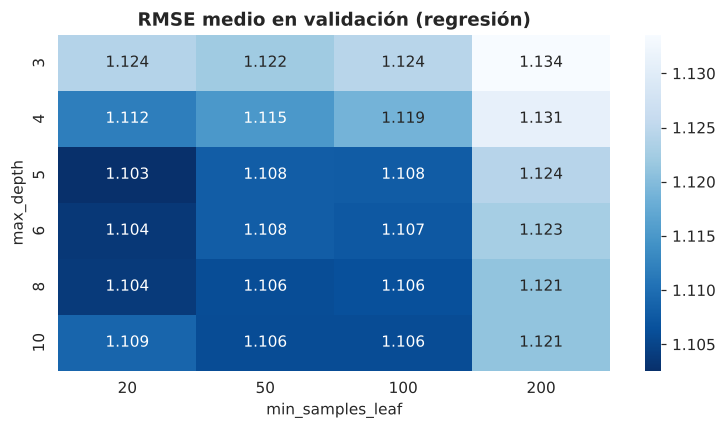

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(cv_reg.pivot(index="max_depth", columns="min_samples_leaf", values="RMSE val"),
            annot=True, fmt=".3f", cmap="Blues_r", ax=ax)
ax.set_title("RMSE medio en validación (regresión)")
plt.tight_layout(); plt.savefig(PLOTS / "arbol_cv_regresion.png", bbox_inches="tight"); plt.show()

In [6]:
mejor_reg = cv_reg.iloc[0]
PAR_REG = dict(max_depth=int(mejor_reg["max_depth"]), min_samples_leaf=int(mejor_reg["min_samples_leaf"]))
print("Hiperparámetros elegidos:", PAR_REG)

arbol_reg = DecisionTreeRegressor(**PAR_REG, random_state=SEED).fit(train[F], train["casos"])
train["pred_arbol"] = arbol_reg.predict(train[F])
test["pred_arbol"] = arbol_reg.predict(test[F])
print(f"Hojas: {arbol_reg.get_n_leaves()} | profundidad: {arbol_reg.get_depth()}")

Hiperparámetros elegidos: {'max_depth': 5, 'min_samples_leaf': 20}
Hojas: 29 | profundidad: 5


### 3.1 Resultados frente a las líneas base

In [7]:
ESCALA_MASE = (train["casos"] - train["lag12"]).abs().mean()   # igual que en el baseline

def metricas_regresion(y, p):
    mae = mean_absolute_error(y, p)
    return {"RMSE": rmse(y, p), "MAE": mae, "MASE": mae / ESCALA_MASE}

preds = {"B1 · último mes (lag1)": "lag1", "B2 · mismo mes del año anterior (lag12)": "lag12",
         "M2 · árbol de decisión": "pred_arbol"}
filas = []
for conj, df in [("Entrenamiento", train), ("Prueba", test)]:
    for nombre, col in preds.items():
        filas.append({"Conjunto": conj, "Modelo": nombre, **metricas_regresion(df["casos"], df[col])})
    if conj == "Prueba":
        filas.append({"Conjunto": conj, "Modelo": "Ref · siempre 0", **metricas_regresion(df["casos"], 0 * df["casos"])})
reg = pd.DataFrame(filas)
ref_b2 = reg[reg["Modelo"].str.startswith("B2")].set_index("Conjunto")["MAE"]
reg["MAE / MAE de B2"] = reg["MAE"] / reg["Conjunto"].map(ref_b2)
reg

,Conjunto,Modelo,RMSE,MAE,MASE,MAE / MAE de B2
0,Entrenamiento,B1 · último mes (lag1),1.642,0.816,0.894,0.894
1,Entrenamiento,B2 · mismo mes del año anterior (lag12),1.823,0.913,1.000,1.000
2,Entrenamiento,M2 · árbol de decisión,1.299,0.768,0.841,0.841
3,Prueba,B1 · último mes (lag1),1.142,0.537,0.588,0.891
4,Prueba,B2 · mismo mes del año anterior (lag12),1.222,0.603,0.660,1.000
5,Prueba,M2 · árbol de decisión,0.907,0.576,0.631,0.956
6,Prueba,Ref · siempre 0,1.054,0.413,0.453,0.686


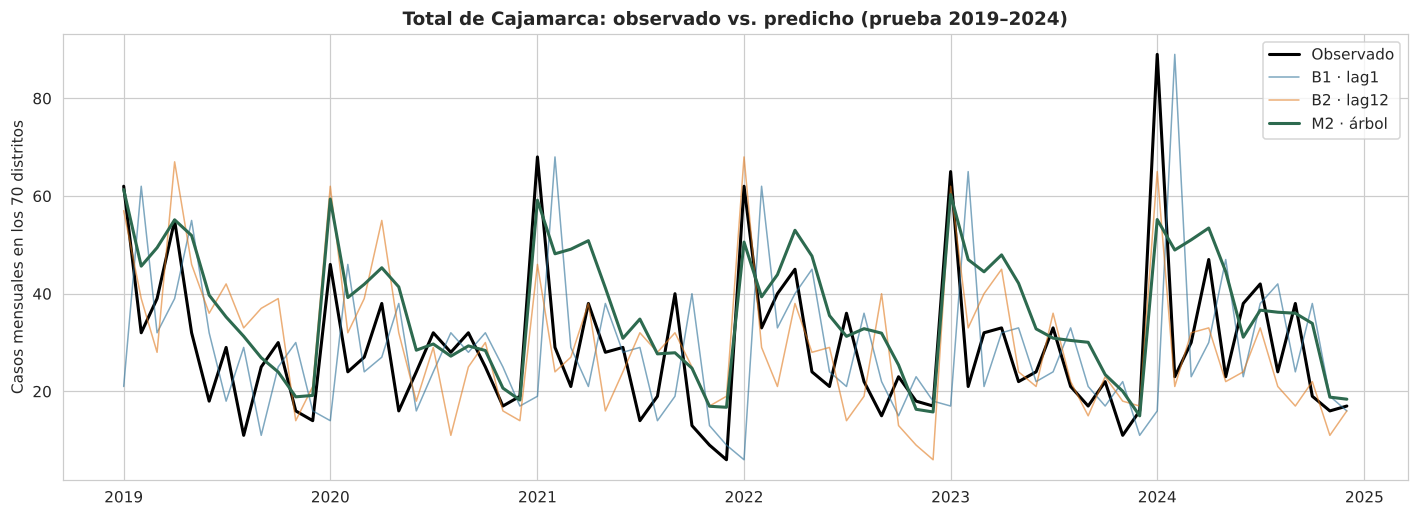

Correlación con el total observado: {'B1': np.float64(-0.073), 'B2': np.float64(0.717), 'M2': np.float64(0.704)}


In [8]:
# Predicho vs. observado: total de Cajamarca mes a mes (paper 2: un RMSE bajo puede esconder un mal ajuste)
tot = test.groupby("fecha_mes")[["casos", "lag1", "lag12", "pred_arbol"]].sum()
fig, ax = plt.subplots(figsize=(13, 4.8))
ax.plot(tot.index, tot["casos"], color="black", lw=2, label="Observado")
ax.plot(tot.index, tot["lag1"], color=AZUL, lw=1, alpha=0.6, label="B1 · lag1")
ax.plot(tot.index, tot["lag12"], color=NARANJA, lw=1, alpha=0.6, label="B2 · lag12")
ax.plot(tot.index, tot["pred_arbol"], color=VERDE, lw=2, label="M2 · árbol")
ax.set_ylabel("Casos mensuales en los 70 distritos")
ax.set_title("Total de Cajamarca: observado vs. predicho (prueba 2019–2024)"); ax.legend()
plt.tight_layout(); plt.savefig(PLOTS / "arbol_total_observado_vs_predicho.png", bbox_inches="tight"); plt.show()
print("Correlación con el total observado:",
      {k: round(np.corrcoef(tot["casos"], tot[c])[0, 1], 3) for k, c in [("B1", "lag1"), ("B2", "lag12"), ("M2", "pred_arbol")]})

In [9]:
por_anio = (test.assign(anio=test["fecha_mes"].dt.year).groupby("anio")
            .apply(lambda g: pd.Series({"casos": g["casos"].sum(),
                                        "RMSE B1": rmse(g["casos"], g["lag1"]),
                                        "RMSE M2": rmse(g["casos"], g["pred_arbol"]),
                                        "MAE B1": mean_absolute_error(g["casos"], g["lag1"]),
                                        "MAE M2": mean_absolute_error(g["casos"], g["pred_arbol"])})))
por_anio

,casos,RMSE B1,RMSE M2,MAE B1,MAE M2
anio,,,,,
2019,363.000,1.104,0.874,0.596,0.612
2020,328.000,1.017,0.831,0.501,0.568
2021,314.000,1.138,0.936,0.487,0.564
2022,356.000,1.166,0.940,0.504,0.549
2023,317.000,1.154,0.853,0.506,0.556
2024,406.000,1.258,0.997,0.627,0.607


## 4. Alerta: clasificación

Se prueban dos conjuntos de variables:
- **Base:** las mismas 7 variables de la regresión.
- **Relativa:** las 7 más los conteos divididos entre el umbral del distrito (`lag1 / umbral`, …). La alerta se define contra el umbral *de cada distrito*, y un árbol sin esa información no puede saber si 3 casos son muchos o pocos para un distrito. El umbral se calcula solo con entrenamiento, así que no hay fuga, pero esta variante usa `umbral` como insumo, y el pipeline lo marcaba como auxiliar. Ver la nota en las conclusiones.

El criterio de elección es el **PR-AUC medio en validación**, por el desbalance (4–5 % de alertas).

In [10]:
REL = [c + "_rel" for c in pp.CONTEOS]
for df in (train, test):
    for c in pp.CONTEOS:
        df[c + "_rel"] = df[c] / df["umbral"]
VARIANTES = {"base": F, "relativa": F + REL}

def oof_proba(feats, d, l):
    # Probabilidades fuera de pliegue (out-of-fold) en los 5 años de validación
    out = pd.Series(np.nan, index=train.index)
    for tr, va in FOLDS:
        m = DecisionTreeClassifier(max_depth=d, min_samples_leaf=l, class_weight="balanced", random_state=SEED)
        m.fit(train.loc[tr, feats], train.loc[tr, "alerta"])
        out.iloc[va] = m.predict_proba(train.loc[va, feats])[:, 1]
    return out

filas = []
for var, feats in VARIANTES.items():
    for d, l in GRID:
        pr = []
        for tr, va in FOLDS:
            m = DecisionTreeClassifier(max_depth=d, min_samples_leaf=l, class_weight="balanced", random_state=SEED)
            m.fit(train.loc[tr, feats], train.loc[tr, "alerta"])
            pr.append(average_precision_score(train.loc[va, "alerta"], m.predict_proba(train.loc[va, feats])[:, 1]))
        filas.append({"variables": var, "max_depth": d, "min_samples_leaf": l, "PR-AUC val": np.mean(pr)})
cv_ale = pd.DataFrame(filas).sort_values("PR-AUC val", ascending=False)
b1_val = np.mean([average_precision_score(train.loc[va, "alerta"], train.loc[va, "lag1_rel"]) for _, va in FOLDS])
print(f"PR-AUC en validación de B1: {b1_val:.3f}")
cv_ale.groupby("variables").head(3)

PR-AUC en validación de B1: 0.116


,variables,max_depth,min_samples_leaf,PR-AUC val
38,relativa,6,100,0.126
42,relativa,8,100,0.122
46,relativa,10,100,0.120
22,base,10,100,0.102
21,base,10,50,0.101
18,base,8,100,0.100


In [11]:
mejor = {v: cv_ale[cv_ale["variables"] == v].iloc[0] for v in VARIANTES}
arboles_ale, umbrales_prob = {}, {}
for v, fila in mejor.items():
    d, l = int(fila["max_depth"]), int(fila["min_samples_leaf"])
    # Umbral de probabilidad: el que maximiza F1 en las predicciones fuera de pliegue (sin mirar la prueba)
    oof = oof_proba(VARIANTES[v], d, l)
    mask = oof.notna()
    p, r, t = precision_recall_curve(train.loc[mask, "alerta"], oof[mask])
    f1 = 2 * p * r / np.where(p + r == 0, 1, p + r)
    umbrales_prob[v] = t[np.argmax(f1[:-1])]
    arboles_ale[v] = DecisionTreeClassifier(max_depth=d, min_samples_leaf=l, class_weight="balanced",
                                            random_state=SEED).fit(train[VARIANTES[v]], train["alerta"])
    print(f"{v}: max_depth={d}, min_samples_leaf={l}, umbral de probabilidad={umbrales_prob[v]:.3f}")

base: max_depth=10, min_samples_leaf=100, umbral de probabilidad=0.755


relativa: max_depth=6, min_samples_leaf=100, umbral de probabilidad=0.726


### 4.1 Resultados frente a las líneas base

In [12]:
def metricas_alerta(y, puntaje, pred):
    return {"Precisión": precision_score(y, pred, zero_division=0), "Recall": recall_score(y, pred, zero_division=0),
            "F1": f1_score(y, pred, zero_division=0), "PR-AUC": average_precision_score(y, puntaje),
            "AUC-ROC": roc_auc_score(y, puntaje), "Alertas predichas": int(pred.sum())}

filas = []
for conj, df in [("Entrenamiento", train), ("Prueba", test)]:
    for nombre, col in [("B1 · último mes (lag1)", "lag1"), ("B2 · mismo mes del año anterior (lag12)", "lag12")]:
        filas.append({"Conjunto": conj, "Modelo": nombre,
                      **metricas_alerta(df["alerta"], df[col] / df["umbral"], (df[col] > df["umbral"]).astype(int))})
    for v, m in arboles_ale.items():
        prob = m.predict_proba(df[VARIANTES[v]])[:, 1]
        df[f"prob_{v}"] = prob
        filas.append({"Conjunto": conj, "Modelo": f"M2 · árbol ({v})",
                      **metricas_alerta(df["alerta"], prob, (prob >= umbrales_prob[v]).astype(int))})
ale = pd.DataFrame(filas)
print(f"Alertas reales en la prueba: {int(test['alerta'].sum())} ({test['alerta'].mean():.2%}, PR-AUC al azar)")
ale

Alertas reales en la prueba: 183 (3.63%, PR-AUC al azar)


,Conjunto,Modelo,Precisión,Recall,F1,PR-AUC,AUC-ROC,Alertas predichas
0,Entrenamiento,B1 · último mes (lag1),0.194,0.194,0.194,0.119,0.671,744
1,Entrenamiento,B2 · mismo mes del año anterior (lag12),0.106,0.103,0.105,0.066,0.577,729
2,Entrenamiento,M2 · árbol (base),0.207,0.281,0.239,0.163,0.781,1008
3,Entrenamiento,M2 · árbol (relativa),0.212,0.387,0.274,0.191,0.808,1356
4,Prueba,B1 · último mes (lag1),0.213,0.213,0.213,0.153,0.689,183
5,Prueba,B2 · mismo mes del año anterior (lag12),0.123,0.126,0.124,0.090,0.598,187
6,Prueba,M2 · árbol (base),0.147,0.131,0.139,0.103,0.737,163
7,Prueba,M2 · árbol (relativa),0.176,0.301,0.222,0.155,0.802,313


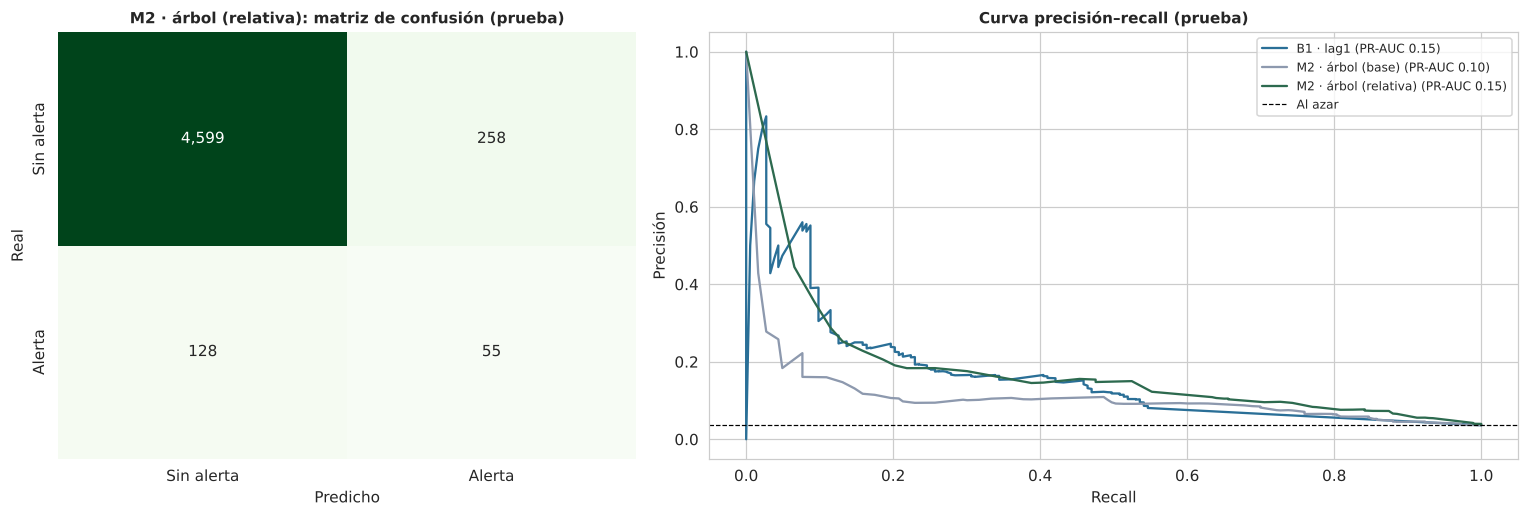

Árbol (relativa): detecta 55 de 183 alertas, 258 falsas alarmas (4.7 por acierto)


In [13]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1.4]})
pred_rel = (test["prob_relativa"] >= umbrales_prob["relativa"]).astype(int)
sns.heatmap(confusion_matrix(test["alerta"], pred_rel), annot=True, fmt=",d", cmap="Greens", cbar=False, ax=ax[0],
            xticklabels=["Sin alerta", "Alerta"], yticklabels=["Sin alerta", "Alerta"])
ax[0].set_title("M2 · árbol (relativa): matriz de confusión (prueba)", fontsize=10)
ax[0].set_xlabel("Predicho"); ax[0].set_ylabel("Real")
for nombre, puntaje, color in [("B1 · lag1", test["lag1"] / test["umbral"], AZUL),
                               ("M2 · árbol (base)", test["prob_base"], GRIS),
                               ("M2 · árbol (relativa)", test["prob_relativa"], VERDE)]:
    p, r, _ = precision_recall_curve(test["alerta"], puntaje)
    ax[1].plot(r, p, color=color, label=f"{nombre} (PR-AUC {average_precision_score(test['alerta'], puntaje):.2f})")
ax[1].axhline(test["alerta"].mean(), color="black", ls="--", lw=0.8, label="Al azar")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precisión"); ax[1].set_title("Curva precisión–recall (prueba)", fontsize=10)
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(PLOTS / "arbol_alertas.png", bbox_inches="tight"); plt.show()

tn, fp, fn, tp = confusion_matrix(test["alerta"], pred_rel).ravel()
print(f"Árbol (relativa): detecta {tp} de {tp + fn} alertas, {fp} falsas alarmas ({fp / tp:.1f} por acierto)")

## 5. Interpretabilidad (paso 9)

Importancia por permutación sobre la prueba y lectura de las reglas. Para que las reglas se puedan leer en el reporte, se muestra también un árbol de solo 3 niveles entrenado igual. El modelo evaluado es el de la sección 3, no este.

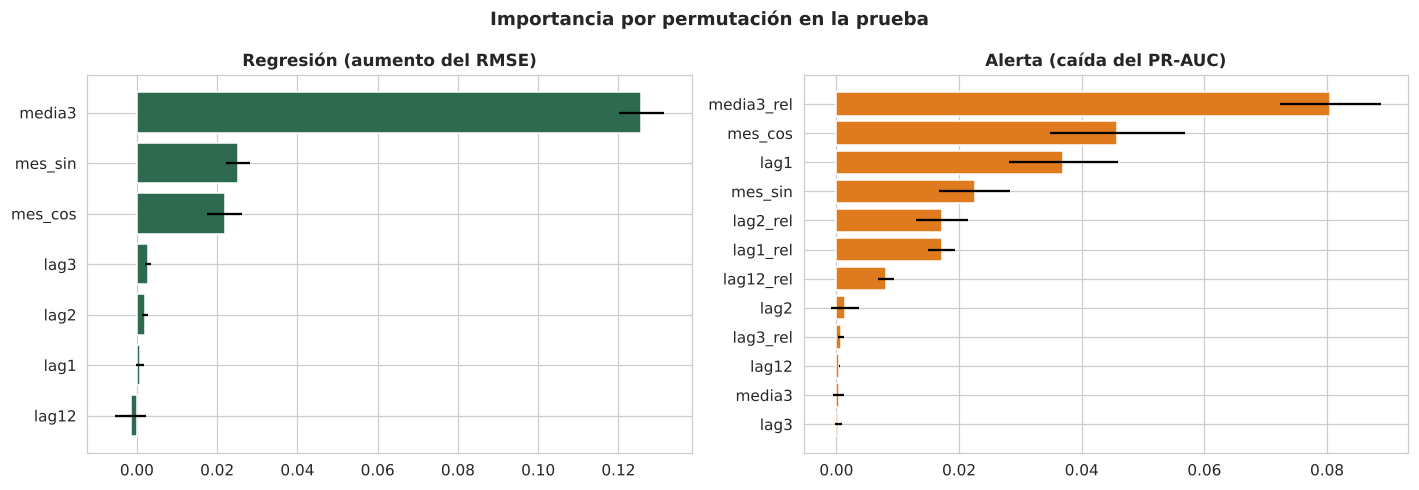

In [14]:
imp = permutation_importance(arbol_reg, test[F], test["casos"], scoring="neg_root_mean_squared_error",
                             n_repeats=20, random_state=SEED)
imp_a = permutation_importance(arboles_ale["relativa"], test[VARIANTES["relativa"]], test["alerta"],
                               scoring="average_precision", n_repeats=20, random_state=SEED)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, im, cols, titulo, color in [(ax[0], imp, F, "Regresión (aumento del RMSE)", VERDE),
                                   (ax[1], imp_a, VARIANTES["relativa"], "Alerta (caída del PR-AUC)", NARANJA)]:
    s = pd.Series(im.importances_mean, index=cols).sort_values()
    a.barh(s.index, s.values, xerr=pd.Series(im.importances_std, index=cols)[s.index], color=color)
    a.set_title(titulo, fontsize=11)
plt.suptitle("Importancia por permutación en la prueba", fontweight="bold")
plt.tight_layout(); plt.savefig(PLOTS / "arbol_importancia.png", bbox_inches="tight"); plt.show()

Árbol de 3 niveles: RMSE en prueba 0.917 (el elegido: 0.907)
|--- media3 <= 2.17
|   |--- media3 <= 0.83
|   |   |--- media3 <= 0.17
|   |   |   |--- value: [0.26]
|   |   |--- media3 >  0.17
|   |   |   |--- value: [0.53]
|   |--- media3 >  0.83
|   |   |--- lag12 <= 1.50
|   |   |   |--- value: [0.91]
|   |   |--- lag12 >  1.50
|   |   |   |--- value: [1.62]
|--- media3 >  2.17
|   |--- media3 <= 5.50
|   |   |--- media3 <= 3.83
|   |   |   |--- value: [2.18]
|   |   |--- media3 >  3.83
|   |   |   |--- value: [3.56]
|   |--- media3 >  5.50
|   |   |--- lag1 <= 13.50
|   |   |   |--- value: [5.49]
|   |   |--- lag1 >  13.50
|   |   |   |--- value: [9.49]



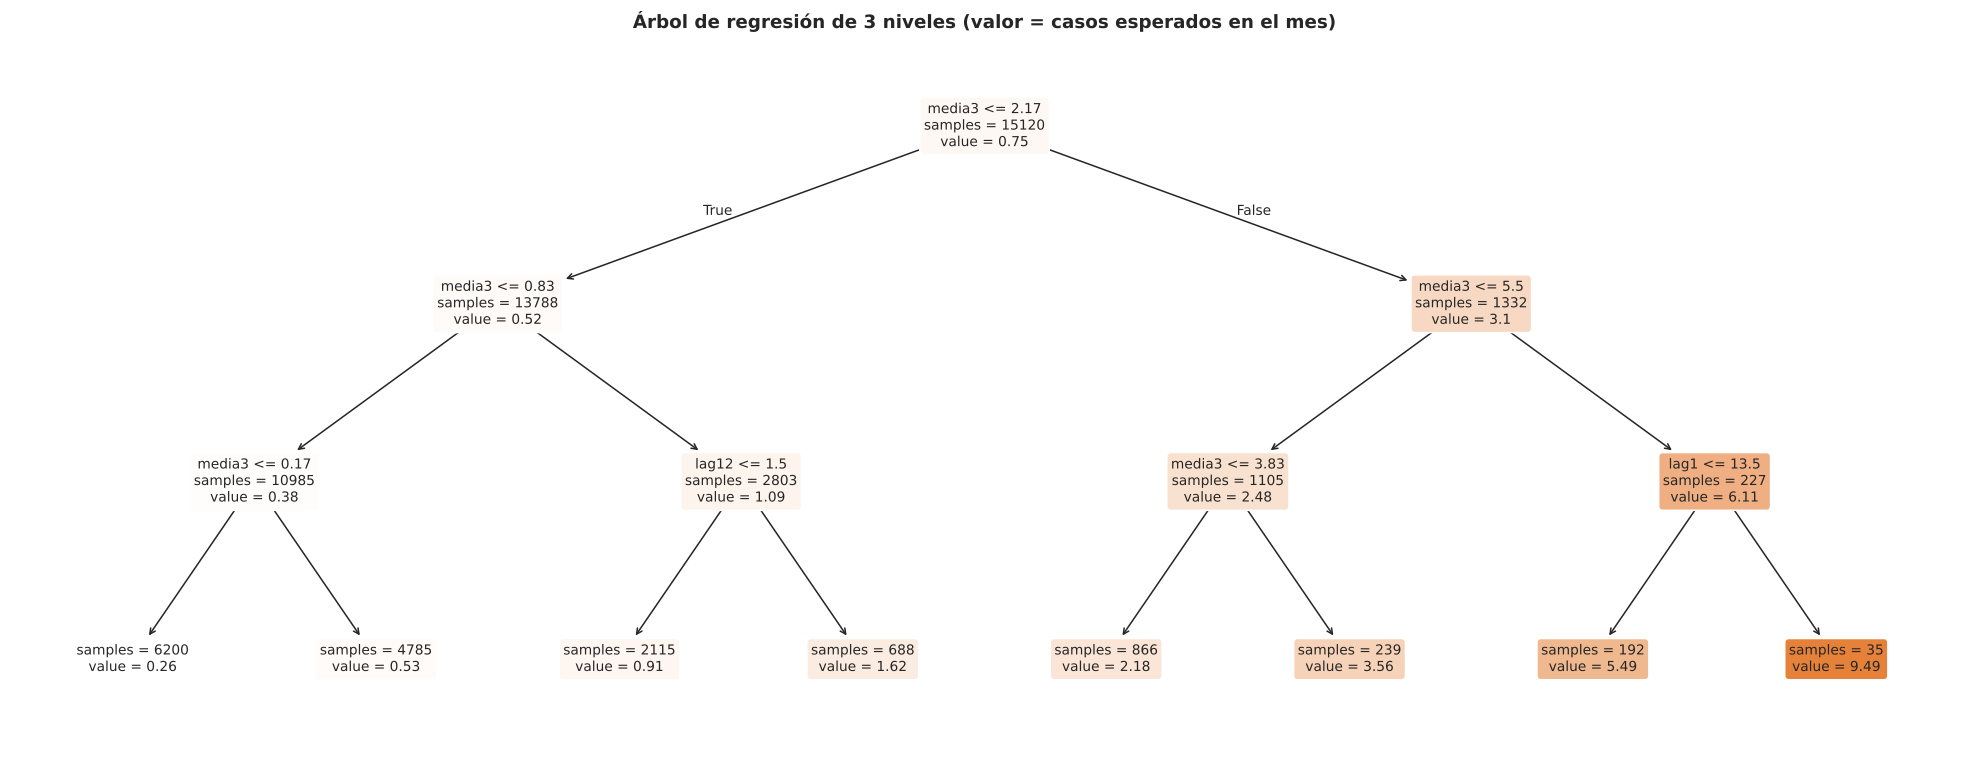

In [15]:
arbol_corto = DecisionTreeRegressor(max_depth=3, min_samples_leaf=PAR_REG["min_samples_leaf"],
                                    random_state=SEED).fit(train[F], train["casos"])
print(f"Árbol de 3 niveles: RMSE en prueba {rmse(test['casos'], arbol_corto.predict(test[F])):.3f} "
      f"(el elegido: {rmse(test['casos'], test['pred_arbol']):.3f})")
reglas = export_text(arbol_corto, feature_names=F, decimals=2)
print(reglas)
(RESULTS / "arbol_reglas.txt").write_text(reglas, encoding="utf-8")

fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(arbol_corto, feature_names=F, filled=True, rounded=True, impurity=False, precision=2, fontsize=9, ax=ax)
ax.set_title("Árbol de regresión de 3 niveles (valor = casos esperados en el mes)")
plt.tight_layout(); plt.savefig(PLOTS / "arbol_reglas.png", bbox_inches="tight"); plt.show()

## 6. Guardar los resultados

In [16]:
tabla = pd.concat([reg.assign(Tarea="Regresión"), ale.assign(Tarea="Alerta")], ignore_index=True)
tabla = tabla[["Tarea", "Conjunto", "Modelo"] + [c for c in tabla.columns if c not in ("Tarea", "Conjunto", "Modelo")]]
tabla.to_csv(RESULTS / "arbol_metricas.csv", index=False)
print("Guardado:", RESULTS / "arbol_metricas.csv")
tabla[tabla["Conjunto"] == "Prueba"]

Guardado: ../results/arbol_metricas.csv


,Tarea,Conjunto,Modelo,RMSE,MAE,MASE,MAE / MAE de B2,Precisión,Recall,F1,PR-AUC,AUC-ROC,Alertas predichas
3,Regresión,Prueba,B1 · último mes (lag1),1.142,0.537,0.588,0.891,NaN,NaN,NaN,NaN,NaN,NaN
4,Regresión,Prueba,B2 · mismo mes del año anterior (lag12),1.222,0.603,0.660,1.000,NaN,NaN,NaN,NaN,NaN,NaN
5,Regresión,Prueba,M2 · árbol de decisión,0.907,0.576,0.631,0.956,NaN,NaN,NaN,NaN,NaN,NaN
6,Regresión,Prueba,Ref · siempre 0,1.054,0.413,0.453,0.686,NaN,NaN,NaN,NaN,NaN,NaN
11,Alerta,Prueba,B1 · último mes (lag1),NaN,NaN,NaN,NaN,0.213,0.213,0.213,0.153,0.689,183.000
12,Alerta,Prueba,B2 · mismo mes del año anterior (lag12),NaN,NaN,NaN,NaN,0.123,0.126,0.124,0.090,0.598,187.000
13,Alerta,Prueba,M2 · árbol (base),NaN,NaN,NaN,NaN,0.147,0.131,0.139,0.103,0.737,163.000
14,Alerta,Prueba,M2 · árbol (relativa),NaN,NaN,NaN,NaN,0.176,0.301,0.222,0.155,0.802,313.000


## 7. Conclusiones

**Resultados en la prueba (2019–2024)**

| | B1 · último mes | B2 · mismo mes año anterior | M2 · árbol |
|---|---|---|---|
| RMSE (casos por distrito-mes) | 1,14 | 1,22 | **0,91** |
| MAE | **0,54** | 0,60 | 0,58 |
| Correlación con el total mensual de Cajamarca | −0,07 | 0,72 | 0,70 |
| PR-AUC de la alerta (al azar: 0,04) | 0,15 | 0,09 | 0,10 (base) · **0,16** (relativa) |
| AUC-ROC de la alerta | 0,69 | 0,60 | 0,74 (base) · **0,80** (relativa) |
| F1 / recall de la alerta | 0,21 / 0,21 | 0,12 / 0,13 | 0,22 / **0,30** (relativa) |

1. **En regresión, el árbol es el mejor en RMSE.** Con `max_depth=5` y `min_samples_leaf=20` (29 hojas) baja el RMSE de B1 en 21 % y le gana los seis años de prueba. Es el primer modelo que supera a "siempre 0" en RMSE (0,91 frente a 1,05).
2. **En MAE no gana.** Queda un poco por encima de B1 (0,58 frente a 0,54) y lejos de "siempre 0" (0,41), porque cada hoja predice una media y casi nunca predice exactamente 0. El árbol se equivoca poco en los meses con muchos casos y un poco en los muchos meses sin casos.
3. **Sigue la estacionalidad sin llegar tarde.** La correlación con el total mensual (0,70) es casi la de B2 y muy superior a la de B1, que va un mes atrasado. El defecto visible es que sobrestima de febrero a abril, después del pico de enero, porque `media3` todavía arrastra ese pico.
4. **Casi todo el árbol depende de `media3`.** La importancia por permutación la pone muy por encima del resto, seguida del mes (`mes_sin`, `mes_cos`). Los rezagos sueltos casi no aportan una vez que está la media de 3 meses. El árbol de 3 niveles (`results/arbol_reglas.txt`) se lee directamente, por ejemplo: «si la media de los últimos 3 meses supera 5,5 y el mes anterior tuvo más de 13 casos, se esperan unos 9,5 casos», y pierde muy poco (RMSE 0,92).
5. **En alerta, el árbol solo sirve con variables relativas al umbral.** Con las 7 variables base queda por debajo de B1 (PR-AUC 0,10 frente a 0,15), porque no sabe cuál es el umbral de cada distrito. Con los conteos divididos entre el umbral iguala a B1 en PR-AUC y F1, sube el AUC-ROC a 0,80 y **detecta 55 de 183 alertas, frente a 39 de B1**, a cambio de más falsas alarmas (4,7 por acierto frente a 3,7).
6. **Decisión para el grupo:** la variante relativa usa `umbral` como insumo. No hay fuga, porque el umbral sale solo del entrenamiento, pero el pipeline lo marcaba como auxiliar. Si se acepta, conviene que los demás modelos de alerta (M1, M3, M4) usen las mismas variables para que la comparación sea justa.

**Meta para los modelos siguientes.** Regresión: bajar el RMSE de 0,91 sin subir el MAE. Alerta: superar PR-AUC 0,16 y recall 0,30. Las métricas quedan en `results/arbol_metricas.csv`.